# 01 · Embeddings y similitud

**Objetivo:** entender qué es un *embedding* de frase, cómo se compara con la
**similitud coseno** y por qué dos textos «parecidos en significado» quedan cerca
en ese espacio, aunque no compartan las mismas palabras.

En este cuaderno se descarga (o se reutiliza desde `cache-hf/`) un modelo
multilingüe pequeño, apto para CPU y para español:

`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`

No hay un LLM todavía: solo la red que convierte una frase en un vector.


## 1. Entorno y mandos

Los mandos de este cuaderno están en la celda siguiente, junto al *bootstrap*.
Cambia el nombre del modelo si quieres probar, por ejemplo,
`intfloat/multilingual-e5-small` (en ese caso las consultas suelen ir con el
prefijo `query:` y los documentos con `passage:`; MiniLM no lo necesita).


In [1]:
from pathlib import Path
import os, sys, json, time, gc, textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "rag_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de RAG "
        "(src/rag_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from rag_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    modo_rapido,
    guardar_json,
    cargar_json,
    cargar_corpus,
    cargar_preguntas,
    fragmentar_documentos,
    resumen_fragmentos,
    Codificador,
    similitud_coseno,
    IndiceNumpy,
    IndiceFAISS,
    IndiceBM25,
    fusion_rrf,
    Reranker,
    evaluar_recuperacion,
    construir_mensajes,
    construir_contexto,
    GeneradorLocal,
    contiene_hechos,
    parece_abstencion,
    PipelineRAG,
    evaluar_fidelidad,
    MODELO_EMBEDDINGS_DEFECTO,
    MODELO_RERANKER_DEFECTO,
    MODELO_LLM_DEFECTO,
    MODELO_LLM_RESERVA,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
MODO_RAPIDO = modo_rapido(True)
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")
print(f"Modo rapido: {MODO_RAPIDO}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/rag/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/rag
Dispositivo: cpu
Semilla:     42
Modo rapido: True


In [2]:
# --- Mandos de este cuaderno ---
MODELO_EMB = MODELO_EMBEDDINGS_DEFECTO
print("Modelo de embeddings:", MODELO_EMB)
print("Dispositivo:", DEVICE)


Modelo de embeddings: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dispositivo: cpu


## 2. Qué es un embedding (y qué no)

Un *embedding* de frase es un vector de números (aquí, de unos pocos cientos de
dimensiones) que pretende capturar el **significado** de un texto corto. Si el
modelo es bueno, «¿en qué puerto escucha la API?» y «¿qué puerto expone el
contenedor de retención?» quedarán cerca, aunque no compartan el verbo.

Eso no convierte al vector en una base de datos ni en un razonador. Solo nos da
una forma de **medir cercanía**. La métrica habitual es la **similitud coseno**:
el coseno del ángulo entre dos vectores. Vale 1 si apuntan en la misma
dirección, 0 si son ortogonales y −1 si apuntan al contrario. Cuando
normalizamos los vectores a norma 1, el coseno coincide con el **producto interno**.

La recuperación densa del resto de la serie es, esencialmente: *embebe la
pregunta, embebe cada fragmento, ordena por coseno y quédate los k mejores*.


## 3. Cargar el modelo

La primera vez descarga del orden de 500 MB (queda en `cache-hf/`). En CPU
suele tardar unos segundos en cargar, más la descarga si no está en caché.


In [3]:
t0 = time.perf_counter()
codificador = Codificador(MODELO_EMB, dispositivo_destino=str(DEVICE))
t_carga = time.perf_counter() - t0
print(f"Cargado en {t_carga:.1f} s")
print(f"Dimensión del vector: {codificador.dim}")
print(f"Dispositivo del modelo: {codificador.dispositivo}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Cargado en 3.5 s
Dimensión del vector: 384
Dispositivo del modelo: cpu


/workspace/rag/src/rag_utils.py:594: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  self.dim = int(self.modelo.get_sentence_embedding_dimension())


## 4. Frases en español, de varios temas

Usamos frases cortas de los mismos mundos que el corpus (curso, Docker, MLflow,
NubeAndina). Así veremos, más abajo, **cúmulos** en la PCA: no estamos
clasificando a mano, el espacio las agrupa solo.


In [4]:
frases = [
    # Docker / API
    "La imagen Docker de la API se llama retencion-api:local.",
    "El contenedor expone el puerto 8080 y el healthcheck consulta /salud.",
    "Se construye la imagen con docker build desde la raiz del repositorio.",
    # Kubernetes
    "En Kubernetes la unidad minima de despliegue es el Pod.",
    "El Deployment de ejemplo de la API tiene 2 replicas en el namespace curso-mlops.",
    # MLflow / CI
    "El tracking URI de MLflow en el laboratorio es http://127.0.0.1:5000.",
    "El experimento se llama retencion-clientes y el alias del modelo es champion.",
    "El workflow de GitHub Actions es ci-retencion.yml y exige 80 % de cobertura.",
    # Reglamento del curso
    "La nota minima de aprobacion del curso es 11 sobre 20.",
    "La asistencia minima exigida es del 70 por ciento de las sesiones.",
    "El Avance 3 se entrega el viernes de la semana 4 en Classroom.",
    # NubeAndina
    "NubeAndina es una empresa ficticia fundada en Chachapoyas en 2019.",
    "Un empleado de NubeAndina tiene 22 dias laborables de vacaciones al año.",
    "La DPO de NubeAndina se llama Elena Quispe.",
    "Los datos de clientes no pueden salir de la region southamerica-west1.",
    "El cluster de produccion se llama gke-prod-andina-01.",
]

grupos = (
    ["Docker"] * 3
    + ["Kubernetes"] * 2
    + ["MLflow/CI"] * 3
    + ["Curso"] * 3
    + ["NubeAndina"] * 5
)
assert len(grupos) == len(frases)

t0 = time.perf_counter()
E = codificador.codificar(frases, progreso=False)
t_enc = time.perf_counter() - t0
print(f"Matriz de embeddings: {E.shape}  (codificadas en {t_enc:.2f} s)")
print(f"Norma media de los vectores (deberia ser ~1 si estan normalizados): {np.linalg.norm(E, axis=1).mean():.4f}")


Matriz de embeddings: (16, 384)  (codificadas en 1.86 s)
Norma media de los vectores (deberia ser ~1 si estan normalizados): 1.0000


## 5. Matriz de similitud coseno

Cada celda es el coseno entre la frase de la fila y la de la columna. La
diagonal es 1 (una frase consigo misma). Fíjate en que dos frases del mismo
tema puntúan alto aunque el vocabulario no sea idéntico, y en que un tema
lejos (vacaciones frente a Docker) queda cerca de 0.


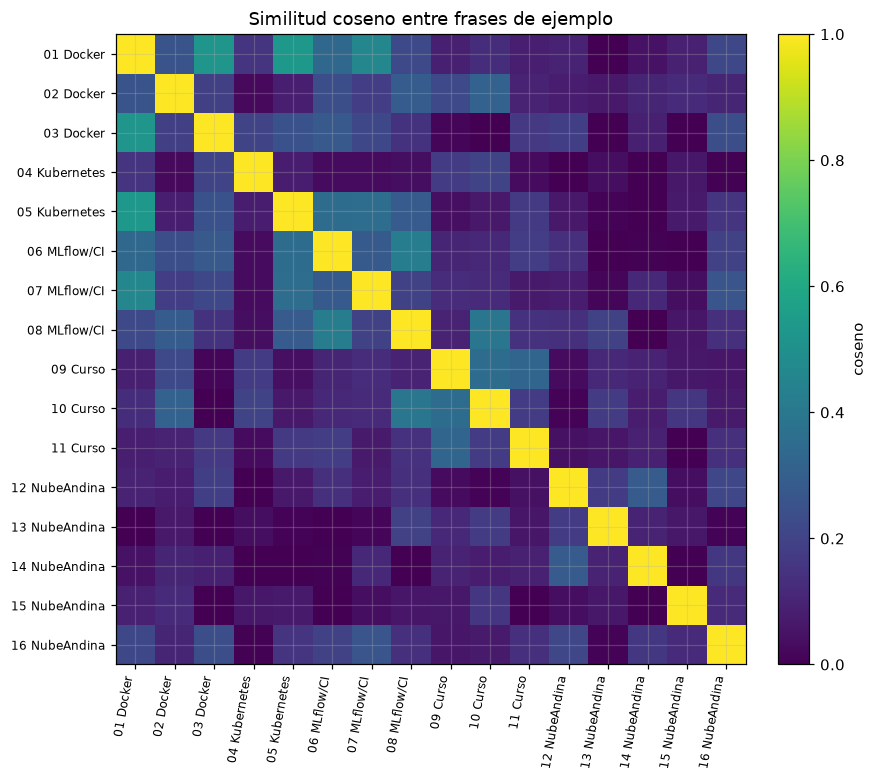

In [5]:
S = similitud_coseno(E, E)
etiquetas = [f"{i+1:02d} {g}" for i, g in enumerate(grupos)]

fig, ax = plt.subplots(figsize=(8.5, 7.2))
im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(frases)))
ax.set_yticks(range(len(frases)))
ax.set_xticklabels(etiquetas, rotation=80, ha="right", fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)
ax.set_title("Similitud coseno entre frases de ejemplo")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="coseno")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_similitud_coseno.png", dpi=130)
plt.show()


## 6. Una consulta: los vecinos más cercanos

Embebemos una pregunta que **no** está en la lista, palabra por palabra, y
ordenamos las frases por coseno. Debería ganar un vecino del tema correcto.


In [6]:
consultas = [
    "¿En qué puerto escucha la API del contenedor?",
    "¿Cuántos días de vacaciones tiene un trabajador de NubeAndina?",
    "¿Cómo se llama el experimento de MLflow del laboratorio?",
]

filas = []
for q in consultas:
    qv = codificador.codificar([q], progreso=False)[0]
    sims = similitud_coseno(qv, E)
    orden = np.argsort(-sims)
    print("=" * 70)
    print("Consulta:", q)
    for rango, i in enumerate(orden[:3], start=1):
        print(f"  {rango}. cos={sims[i]:.3f}  [{grupos[i]}] {frases[i]}")
        filas.append({"consulta": q, "rango": rango, "coseno": float(sims[i]), "grupo": grupos[i], "frase": frases[i]})

pd.DataFrame(filas)


Consulta: ¿En qué puerto escucha la API del contenedor?
  1. cos=0.514  [Docker] La imagen Docker de la API se llama retencion-api:local.
  2. cos=0.469  [Docker] El contenedor expone el puerto 8080 y el healthcheck consulta /salud.
  3. cos=0.399  [Kubernetes] El Deployment de ejemplo de la API tiene 2 replicas en el namespace curso-mlops.


Consulta: ¿Cuántos días de vacaciones tiene un trabajador de NubeAndina?
  1. cos=0.744  [NubeAndina] Un empleado de NubeAndina tiene 22 dias laborables de vacaciones al año.
  2. cos=0.278  [Curso] La asistencia minima exigida es del 70 por ciento de las sesiones.
  3. cos=0.223  [NubeAndina] NubeAndina es una empresa ficticia fundada en Chachapoyas en 2019.


Consulta: ¿Cómo se llama el experimento de MLflow del laboratorio?
  1. cos=0.580  [MLflow/CI] El tracking URI de MLflow en el laboratorio es http://127.0.0.1:5000.
  2. cos=0.398  [MLflow/CI] El experimento se llama retencion-clientes y el alias del modelo es champion.
  3. cos=0.246  [Curso] El Avance 3 se entrega el viernes de la semana 4 en Classroom.


,consulta,rango,coseno,grupo,frase
0,¿En qué puerto escucha la API del contenedor?,1,0.513997,Docker,La imagen Docker de la API se llama retencion-...
1,¿En qué puerto escucha la API del contenedor?,2,0.468723,Docker,El contenedor expone el puerto 8080 y el healt...
2,¿En qué puerto escucha la API del contenedor?,3,0.399193,Kubernetes,El Deployment de ejemplo de la API tiene 2 rep...
3,¿Cuántos días de vacaciones tiene un trabajado...,1,0.743975,NubeAndina,Un empleado de NubeAndina tiene 22 dias labora...
4,¿Cuántos días de vacaciones tiene un trabajado...,2,0.277682,Curso,La asistencia minima exigida es del 70 por cie...
5,¿Cuántos días de vacaciones tiene un trabajado...,3,0.222787,NubeAndina,NubeAndina es una empresa ficticia fundada en ...
6,¿Cómo se llama el experimento de MLflow del la...,1,0.579963,MLflow/CI,El tracking URI de MLflow en el laboratorio es...
7,¿Cómo se llama el experimento de MLflow del la...,2,0.397769,MLflow/CI,El experimento se llama retencion-clientes y e...
8,¿Cómo se llama el experimento de MLflow del la...,3,0.246420,Curso,El Avance 3 se entrega el viernes de la semana...


## 7. Una foto en 2-D: PCA

Diez dimensiones no se dibujan. Una PCA a 2 componentes no es el espacio real
(perdemos información), pero suele bastar para *ver* que los temas forman
grupos. Los ejes no tienen un nombre semántico («eje Docker»): son las
direcciones de mayor varianza.


Varianza explicada por las 2 componentes: [0.141 0.112]
Suma: 0.25282418727874756


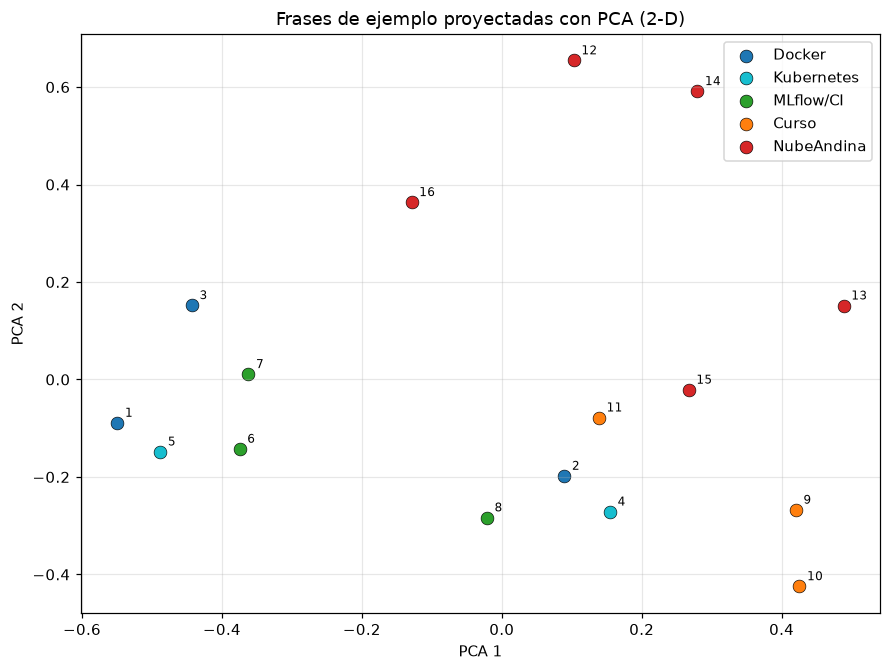

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=SEMILLA)
xy = pca.fit_transform(E)
print("Varianza explicada por las 2 componentes:", pca.explained_variance_ratio_.round(3))
print("Suma:", float(pca.explained_variance_ratio_.sum()))

colores = {
    "Docker": "#1f77b4",
    "Kubernetes": "#17becf",
    "MLflow/CI": "#2ca02c",
    "Curso": "#ff7f0e",
    "NubeAndina": "#d62728",
}

fig, ax = plt.subplots(figsize=(8.2, 6.2))
for g in colores:
    mask = np.array(grupos) == g
    ax.scatter(xy[mask, 0], xy[mask, 1], c=colores[g], s=70, label=g, edgecolors="k", linewidths=0.4)
    for i in np.where(mask)[0]:
        ax.annotate(str(i + 1), (xy[i, 0], xy[i, 1]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_title("Frases de ejemplo proyectadas con PCA (2-D)")
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_pca_embeddings.png", dpi=130)
plt.show()


## 8. Una nota sobre otros modelos (E5)

Modelos como `intfloat/multilingual-e5-small` están entrenados con **prefijos**:
las consultas van como `query: ...` y los documentos como `passage: ...`. Si te
olvidas del prefijo, la similitud se degrada. MiniLM, el que usamos por defecto
en esta serie, no pide esos prefijos. Si cambias de modelo, lee su ficha en el
Hub antes de indexar el corpus entero.

## Recapitulando

- Un embedding es un vector; la similitud coseno mide cercanía semántica.
- Ese es el motor de la **búsqueda densa** que usaremos para recuperar fragmentos.
- En el cuaderno 02 troceamos documentos reales y construimos un índice (NumPy y FAISS).

Siguiente: [02-chunking-e-indexado.ipynb](02-chunking-e-indexado.ipynb).


In [8]:
guardar_json(
    {
        "modelo": MODELO_EMB,
        "dim": int(codificador.dim),
        "n_frases": len(frases),
        "segundos_carga": round(t_carga, 3),
        "segundos_codificar": round(t_enc, 3),
        "varianza_pca": [float(x) for x in pca.explained_variance_ratio_],
    },
    RUTAS["resultados"] / "embeddings.json",
)
print("Metricas escritas en resultados/embeddings.json")


Metricas escritas en resultados/embeddings.json
